Decision Tree Regressor

In [167]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/death_clean.csv")
df

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...
...,...,...,...,...,...,...,...,...
545,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2016,1,0,Profil Kesehatan Indonesia Tahun 2016,Lampiran 6.37,https://pusdatin.kemkes.go.id/download.php?fil...
546,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2017,1,0,Profil Kesehatan Indonesia Tahun 2017,Lampiran 6.43,https://pusdatin.kemkes.go.id/download.php?fil...
547,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2019,1,0,Profil Kesehatan Indonesia Tahun 2019,Lampiran 63.c,https://pusdatin.kemkes.go.id/download.php?fil...
548,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2020,1,0,Profil Kesehatan Indonesia Tahun 2020,191,https://pusdatin.kemkes.go.id/download.php?fil...


In [168]:
x = df[["Cause", "Type"]]
y = df[["Total Deaths"]]

x_encode = pd.get_dummies(x, columns=["Cause", "Type"])

scale = MinMaxScaler()
y_norm = scale.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encode, y_norm, random_state=42, test_size=0.3)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 385, x_test = 165
y_train = 385, y_test = 165


In [169]:
model = DecisionTreeRegressor()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([0.12955149, 0.07946554, 0.04360056, 0.06153305, 0.10873093,
       0.10873093, 0.07946554, 0.        , 0.00803697, 0.0323488 ,
       0.        , 0.60970464, 0.07946554, 0.17862166, 0.41772152,
       0.07946554, 0.        , 0.60970464, 0.01054852, 0.0323488 ,
       0.03164557, 0.27707454, 0.30098453, 0.0121894 , 0.07946554,
       0.        , 0.        , 0.02756681, 0.10423504, 0.10423504,
       0.01172058, 0.        , 0.        , 0.07946554, 0.03248945,
       0.07946554, 0.60970464, 0.27707454, 0.08415377, 0.08415377,
       0.12955149, 0.        , 0.0140647 , 0.07946554, 0.03248945,
       0.35864979, 0.10873093, 0.10423504, 0.02390999, 0.10423504,
       0.03164557, 0.02208158, 0.        , 0.        , 0.01312705,
       0.00225035, 0.10873093, 0.10873093, 0.1203171 , 0.69057665,
       0.        , 0.        , 0.01898734, 0.28691983, 0.06153305,
       0.60970464, 0.19878106, 0.35864979, 0.10873093, 0.1203171 ,
       0.07946554, 0.        , 0.01312705, 0.00843882, 0.07946

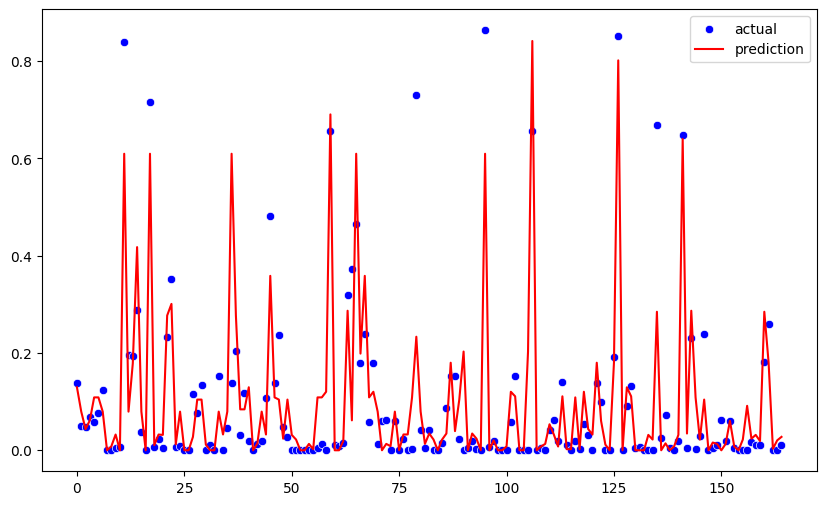

In [170]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.scatterplot(x = range(len(y_test)), y = y_test, color = "blue", label = "actual")
sns.lineplot(x = range(len(y_test)), y = y_pred, color = "red", label = "prediction")
plt.show()

In [171]:
score = model.score(x_test, y_test)
print(f"Skor = {score * 100 :.2f}%")

Skor = 75.04%


In [172]:
importance = model.feature_importances_

feature_name = x_train.columns

importance_df = pd.DataFrame({
    "Feature" : feature_name,
    "Importance" : importance
})

importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
0,Cause_AIDS,0.152764
24,Cause_Demam Berdarah Dengue (DBD),0.125555
34,Cause_Gangguan saluran napas lainnya yang berh...,0.086984
119,"Cause_Malformasi, Deformasi Kongenital & Kelai...",0.076848
108,Cause_Kronis Filariasis,0.063348
...,...,...
1,Cause_Abrasi Air Laut,0.000000
73,Cause_KLB Malaria Klinis,0.000000
72,Cause_KLB Malaria Falsiparum,0.000000
70,Cause_KLB Leptospirosis,0.000000


In [173]:
import graphviz
from io import StringIO
from sklearn.tree import export_graphviz

x_encode.columns = x_encode.columns.str.replace('[^a-zA-Z0-9]', '_', regex=True)

dot_data = StringIO()
export_graphviz(model, out_file=dot_data, 
                feature_names=x_encode.columns,
                filled=True, rounded=True, special_characters=False)

graph = graphviz.Source(dot_data.getvalue())

graph.render("decision_tree", format='pdf')

graph.view()

'decision_tree.pdf'

In [174]:
test_data = pd.DataFrame({
    "Cause" : ["Gempa Bumi", "Banjir", "Kebakaran", "Tsunami", "Angin Puting Beliung", "Tanah Longsor"],
    "Type" : ["Bencana Alam"] * 6
})

test_data

,Cause,Type
0,Gempa Bumi,Bencana Alam
1,Banjir,Bencana Alam
2,Kebakaran,Bencana Alam
3,Tsunami,Bencana Alam
4,Angin Puting Beliung,Bencana Alam
5,Tanah Longsor,Bencana Alam


In [175]:
test_encode = pd.get_dummies(test_data, columns=["Cause", "Type"])
column = pd.get_dummies(x[["Cause", "Type"]]).columns
test_encode

,Cause_Angin Puting Beliung,Cause_Banjir,Cause_Gempa Bumi,Cause_Kebakaran,Cause_Tanah Longsor,Cause_Tsunami,Type_Bencana Alam
0,False,False,True,False,False,False,True
1,False,True,False,False,False,False,True
2,False,False,False,True,False,False,True
3,False,False,False,False,False,True,True
4,True,False,False,False,False,False,True
5,False,False,False,False,True,False,True


In [176]:
test_encode = test_encode.reindex(columns = column, fill_value=0)
test_encode

,Cause_AIDS,Cause_Abrasi Air Laut,Cause_Aksi Teror dan Sabotase,Cause_Angin Puting Beliung,Cause_Angin Siklon Tropis,Cause_Angin Topan,Cause_Angin Topan / Angin Puting Beliung / Angin Puyuh,Cause_Angin kencang,Cause_Angin siklon tropis (angin kencang dan angin puting beliung),Cause_Antraks,...,Cause_Rubella,Cause_Tanah Longsor,Cause_Tersambar Petir,Cause_Tetanus,Cause_Tetanus Neonatorium,Cause_Tsunami,Cause_Wabah Penyakit (Epidemi),Type_Bencana Alam,Type_Bencana Non Alam dan Penyakit,Type_Bencana Sosial
0,0,0,0,False,0,0,0,0,0,0,...,0,False,0,0,0,False,0,True,0,0
1,0,0,0,False,0,0,0,0,0,0,...,0,False,0,0,0,False,0,True,0,0
2,0,0,0,False,0,0,0,0,0,0,...,0,False,0,0,0,False,0,True,0,0
3,0,0,0,False,0,0,0,0,0,0,...,0,False,0,0,0,True,0,True,0,0
4,0,0,0,True,0,0,0,0,0,0,...,0,False,0,0,0,False,0,True,0,0
5,0,0,0,False,0,0,0,0,0,0,...,0,True,0,0,0,False,0,True,0,0


In [177]:
prediction = model.predict(test_encode)
result = scale.inverse_transform(prediction.reshape(-1,1)).ravel().astype(int)

In [178]:
prediction

array([0.12955149, 0.07946554, 0.03445851, 0.20300047, 0.02039381,
       0.10423504])

In [179]:
prediction.reshape(-1,1)

array([[0.12955149],
       [0.07946554],
       [0.03445851],
       [0.20300047],
       [0.02039381],
       [0.10423504]])

In [180]:
scale.inverse_transform(prediction.reshape(-1,1))

array([[ 92.11111111],
       [ 56.5       ],
       [ 24.5       ],
       [144.33333333],
       [ 14.5       ],
       [ 74.11111111]])

In [181]:
scale.inverse_transform(prediction.reshape(-1,1)).ravel()

array([ 92.11111111,  56.5       ,  24.5       , 144.33333333,
        14.5       ,  74.11111111])

In [182]:
scale.inverse_transform(prediction.reshape(-1,1)).ravel().astype(int)

array([ 92,  56,  24, 144,  14,  74])

In [183]:
test_data["Total Deaths"] = result
test_data

,Cause,Type,Total Deaths
0,Gempa Bumi,Bencana Alam,92
1,Banjir,Bencana Alam,56
2,Kebakaran,Bencana Alam,24
3,Tsunami,Bencana Alam,144
4,Angin Puting Beliung,Bencana Alam,14
5,Tanah Longsor,Bencana Alam,74


Decision Tree Classifier

In [184]:
from sklearn.tree import DecisionTreeClassifier
import numpy as np

np.random.seed(42)
age = np.random.randint(18, 60, size=200)
income = np.random.randint(20000, 120000, size=200)
education = np.random.randint(1, 5, size=200)
purchase = np.random.randint(0, 2, size=200)

df = pd.DataFrame({
    "Age" : age,
    "Income" : income,
    "Education" : education,
    "Purchase" : purchase
})

df

,Age,Income,Education,Purchase
0,56,45342,2,1
1,46,57157,3,0
2,32,87863,2,0
3,25,72083,3,1
4,38,85733,4,1
...,...,...,...,...
195,23,75609,3,1
196,49,116825,1,1
197,21,76661,3,1
198,28,51024,4,1


In [185]:
x = df[["Age", "Income", "Education"]]
y = df["Purchase"]

scaler = MinMaxScaler()
x_encode = scaler.fit_transform(x)

x_train, x_test, y_train, y_test = train_test_split(x_encode, y, test_size=0.3, random_state=42)

In [186]:
model = DecisionTreeClassifier(random_state=42, ccp_alpha=0.01)
model.fit(x_train, y_train)
score_classifier = model.score(x_test, y_test)

print(f"Skor = {score_classifier * 100 :.2f}%")

Skor = 58.33%


ASSIGNMENT

In [187]:
df = pd.read_csv("car_data.csv")
df

,User ID,Gender,Age,AnnualSalary,Purchased
0,385,Male,35,20000,0
1,681,Male,40,43500,0
2,353,Male,49,74000,0
3,895,Male,40,107500,1
4,661,Male,25,79000,0
...,...,...,...,...,...
995,863,Male,38,59000,0
996,800,Female,47,23500,0
997,407,Female,28,138500,1
998,299,Female,48,134000,1


In [188]:
df.isnull().sum()

User ID         0
Gender          0
Age             0
AnnualSalary    0
Purchased       0
dtype: int64

In [189]:
df.dtypes

User ID          int64
Gender          object
Age              int64
AnnualSalary     int64
Purchased        int64
dtype: object

In [190]:
x = df[["Gender", "Age", "AnnualSalary"]]
y = df["Purchased"]

x = pd.get_dummies(x, columns=["Gender"], drop_first=True)

norm = MinMaxScaler()
x = norm.fit_transform(x[["Age", "AnnualSalary"]])

x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=42, test_size=0.2)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 800, x_test = 200
y_train = 800, y_test = 200


In [191]:
model = DecisionTreeClassifier(random_state=42, ccp_alpha=0.01)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 1])

In [192]:
score = model.score(x_test, y_test)
print(f"Skor = {score * 100 :.2f}%")

Skor = 90.50%


Random Forest

In [193]:
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv("death_clean.csv")
df

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...
...,...,...,...,...,...,...,...,...
545,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2016,1,0,Profil Kesehatan Indonesia Tahun 2016,Lampiran 6.37,https://pusdatin.kemkes.go.id/download.php?fil...
546,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2017,1,0,Profil Kesehatan Indonesia Tahun 2017,Lampiran 6.43,https://pusdatin.kemkes.go.id/download.php?fil...
547,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2019,1,0,Profil Kesehatan Indonesia Tahun 2019,Lampiran 63.c,https://pusdatin.kemkes.go.id/download.php?fil...
548,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2020,1,0,Profil Kesehatan Indonesia Tahun 2020,191,https://pusdatin.kemkes.go.id/download.php?fil...


In [194]:
x = df[["Cause", "Type"]]
y = df[["Total Deaths"]]

x_encode = pd.get_dummies(x, columns=["Cause", "Type"])

scale = MinMaxScaler()
y_norm = scale.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encode, y_norm, random_state=42, test_size=0.3)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 385, x_test = 165
y_train = 385, y_test = 165


In [195]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([1.25279078e-01, 7.52600964e-02, 3.00020092e-02, 6.08771354e-02,
       1.13331298e-01, 1.13331298e-01, 7.52600964e-02, 6.27106914e-04,
       7.70852518e-03, 2.21940928e-02, 8.43881857e-05, 6.07668127e-01,
       7.52600964e-02, 1.48973277e-01, 3.87408345e-01, 7.52600964e-02,
       6.27106914e-04, 6.07668127e-01, 9.28914674e-03, 2.72411314e-02,
       2.84106892e-02, 1.82869198e-01, 1.95937312e-01, 1.24034808e-02,
       7.52600964e-02, 9.06391624e-05, 8.43881857e-05, 2.88788204e-02,
       1.03427489e-01, 1.03427489e-01, 1.13130149e-02, 2.10970464e-04,
       6.27106914e-04, 7.52600964e-02, 3.35240991e-02, 7.52600964e-02,
       6.07668127e-01, 1.82869198e-01, 8.47452448e-02, 8.47452448e-02,
       1.25279078e-01, 7.03234880e-05, 1.06891702e-02, 7.52600964e-02,
       3.35240991e-02, 2.36821378e-01, 1.13331298e-01, 1.03427489e-01,
       2.41544803e-02, 1.03427489e-01, 2.84106892e-02, 2.11661463e-02,
       7.03234880e-05, 6.27106914e-04, 1.23850324e-02, 2.33065908e-03,
      

In [196]:
score = model.score(x_test, y_test)
print(f"Skor = {score * 100 :.2f}%")

Skor = 72.61%


In [199]:
y_test_original = scale.inverse_transform(y_test.reshape(-1,1)).ravel().astype(int)
y_pred_original = scale.inverse_transform(y_pred.reshape(-1,1)).ravel().astype(int)

result_df = pd.DataFrame({
    "Actual" : y_test_original,
    "Prediksi" : y_pred_original
})

result_df

,Actual,Prediksi
0,99,89
1,35,53
2,34,21
3,48,43
4,42,80
...,...,...
160,129,211
161,184,127
162,0,1
163,0,13


In [201]:
import graphviz
from io import StringIO
from sklearn.tree import export_graphviz
import os

x_encode.columns = x_encode.columns.str.replace('[^a-zA-Z0-9]', '_', regex=True)

output_dir = '/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/tree_pdf'

os.makedirs(output_dir, exist_ok=True)

for i, tree in enumerate(model.estimators_):
    dot_data = StringIO()
    export_graphviz(tree, out_file=dot_data, 
                    feature_names=x_encode.columns,
                    filled=True, rounded=True, special_characters=False)
    
    graph = graphviz.Source(dot_data.getvalue())
    tree_filename = os.path.join(output_dir, f"decision_tree_{i}")
    graph.render(tree_filename, format='pdf')
    
    # Jika ingin melihatnya langsung, bisa digunakan perintah view:
    # graph.view(filename=tree_filename)
